# Civet Behavior Classification — ResNet18 on YOLO Crops
Second version of the behavior model. YOLO (from `yolo_train.ipynb`) finds the civet, and ResNet18 is trained on the cropped civet instead of the whole room. The first version (`resnet18_train.ipynb`) is kept as the baseline.

Output files of this notebook start with `cc` (results) or are saved in `civet2/crops/`, so the baseline results are not overwritten.

## Step 1: Setup

1.1 Mount Google Drive

In [15]:
# ===== Cell 1.1: Mount Google Drive (run once per session) =====
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1.2 Imports and configuration

In [16]:
# ===== Cell 1.2: Imports and configuration (run once per session) =====
import re, random, shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---------- Paths ----------
BASE    = Path('/content/drive/MyDrive/civet2')
SRC     = BASE / 'sorted'     # training images (the only source used for training)
MODELS  = BASE / 'models'     # saved models
RESULTS = BASE / 'results'    # figures, tables, reports
MODELS.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
assert 'test' not in SRC.parts, 'Test data must never be used for training'

# ---------- Constants ----------
IMG_EXT = {'.jpg', '.jpeg', '.png'}
CAMERAS = ['A01', 'A02', 'A03', 'A04']
NAME_RE = re.compile(r'(A0[1-4])_(\d{14})_t?(\d{5})')   # e.g. A03_20260405140327_t07460 (some files lack "_t")

# Behavior folder (leaf) -> class used for training
MERGE = {
    'Resting': 'Inactive', 'Sitting': 'Inactive', 'Standing': 'Inactive',
    'Feeding': 'Feeding_Drinking', 'Drinking': 'Feeding_Drinking',
    'Locomotion': 'Locomotion',
    'Not_visible': 'Not_visible',
}
# Training class -> ethogram group
GROUP = {'Inactive': 'Inactive', 'Locomotion': 'Active',
         'Feeding_Drinking': 'Active', 'Not_visible': 'Not visible'}

print('Config loaded. MERGE keys:', list(MERGE))

Config loaded. MERGE keys: ['Resting', 'Sitting', 'Standing', 'Feeding', 'Drinking', 'Locomotion', 'Not_visible']


1.3 Helper functions

In [17]:
# ===== Cell 1.3: Helper functions (run once per session) =====
MERGE_KEYS = {k.lower(): k for k in MERGE}   # case-insensitive lookup

def canonical(folder):
    """Map a folder name to its MERGE key, ignoring case and extra spaces."""
    return MERGE_KEYS.get(folder.strip().lower().replace(' ', '_'))

def parse_name(path):
    """Return (camera, clip_id, seconds_from_clip_start) from a file name, or None."""
    m = NAME_RE.search(Path(path).stem)
    if not m:
        return None
    cam, start, t = m.groups()
    return cam, f'{cam}_{start}', int(t)

def list_images(root):
    """Find all images under root, skipping folders that start with '_' (e.g. _excluded).
    The behavior is the name of the folder that directly contains the image."""
    out = []
    for p in root.rglob('*'):
        if p.suffix.lower() not in IMG_EXT:
            continue
        if any(part.strip().startswith('_') for part in p.relative_to(root).parts):
            continue
        out.append((p, p.parent.name))
    return out

folders = Counter(b for _, b in list_images(SRC))
for f, n in sorted(folders.items()):
    print(f'{f!r:20} {n:5} images -> {canonical(f) or "UNKNOWN"}')

IMG_SIZE = 224

def prep(img_bgr, steps=False):
    """Gray -> Histogram Equalization -> Gaussian 3x3 -> 3 channels -> 224x224 (uint8).
    Must be identical for training, validation and all inference."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    he   = cv2.equalizeHist(gray)
    blur = cv2.GaussianBlur(he, (3, 3), 0)
    out  = cv2.resize(cv2.merge([blur, blur, blur]), (IMG_SIZE, IMG_SIZE),
                      interpolation=cv2.INTER_AREA)
    if steps:
        return {'Original': cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), 'Grayscale': gray,
                'Histogram Eq.': he, 'Gaussian 3x3': blur, 'Final 224x224': out}
    return out

'Drinking'              24 images -> Drinking
'Feeding'              318 images -> Feeding
'Locomotion'           719 images -> Locomotion
'Not_visible'          230 images -> Not_visible
'Resting'              248 images -> Resting
'Sitting'               88 images -> Sitting
'Standing'              73 images -> Standing


## Step C1: Crop the Civet with YOLO
The trained YOLO detector crops the civet from every training image, so ResNet18 sees the animal instead of the whole room (small / far civet, background bias). Not_visible images are only used to measure YOLO false detections.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
best.pt files found: ['/content/drive/MyDrive/civet2/models/yolo_run/weights/best.pt']
Using YOLO weights: /content/drive/MyDrive/civet2/models/yolo_run/weights/best.pt
Images to process: 1700
  200/1700
  400/1700
  600/1700
  800/1700
  1000/1700
  1200/1700
  1400/1700
  1600/1700


,found_rate,found,total
cls,,,
Feeding_Drinking,0.968,331,342
Inactive,0.868,355,409
Locomotion,0.935,672,719
Not_visible,0.000,0,230


Not_visible rows with a detection = YOLO false positives (or a civet in the image).


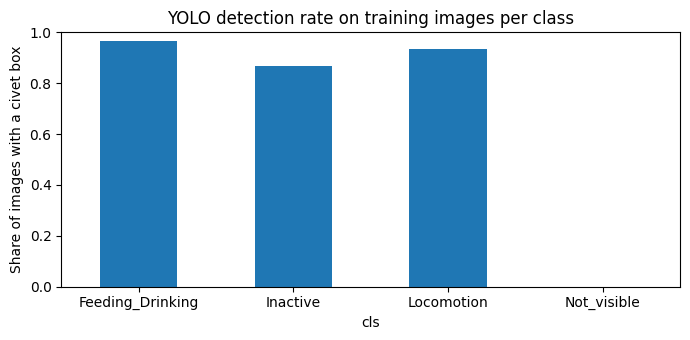

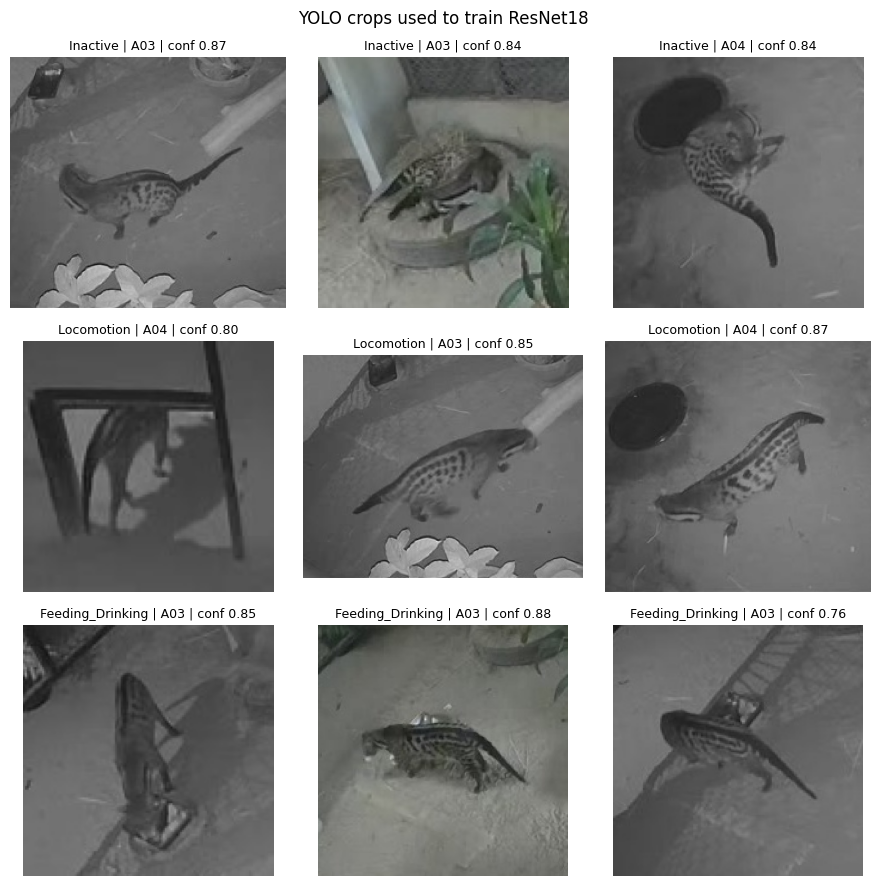

In [ ]:
# ===== Cell C1: Crop the civet from every training image with YOLO =====
# Output: BASE/crops/<behavior>/*.jpg, results/cc1_crops.csv, cc1_found.png, cc1_crop_examples.png
!pip -q install ultralytics
from ultralytics import YOLO

# ---------- YOLO weights: newest best.pt under civet2/ (or set the path by hand) ----------
YOLO_W = None                       # e.g. BASE / 'models' / 'yolo_best.pt'
if YOLO_W is None:
    cands = sorted(BASE.rglob('best.pt'), key=lambda p: p.stat().st_mtime)
    print('best.pt files found:', [str(p) for p in cands])
    assert cands, 'No best.pt found under civet2/ - set YOLO_W by hand'
    YOLO_W = cands[-1]
print('Using YOLO weights:', YOLO_W)

YOLO_CONF = 0.25
MARGIN    = 1.3          # square crop side = 1.3 x longer box side (keeps some context)
CROPS     = BASE / 'crops'
yolo = YOLO(str(YOLO_W))

items = [(p, canonical(f)) for p, f in list_images(SRC)]
items = [(p, b) for p, b in items if b is not None]
print('Images to process:', len(items))

rows = []
for k, (p, beh) in enumerate(items, 1):
    img = cv2.imread(str(p))
    H, W = img.shape[:2]
    r = yolo.predict(img, conf=YOLO_CONF, verbose=False)[0]
    info = parse_name(p)
    row = {'path': str(p), 'behavior': beh, 'cls': MERGE[beh],
           'camera': info[0] if info else None, 'clip': info[1] if info else None,
           't': info[2] if info else None, 'found': len(r.boxes) > 0}
    if row['found']:
        i = int(r.boxes.conf.argmax())
        x1, y1, x2, y2 = r.boxes.xyxy[i].tolist()
        row.update(conf=float(r.boxes.conf[i]), x1=x1, y1=y1, x2=x2, y2=y2)
        if MERGE[beh] != 'Not_visible':
            side = max(x2 - x1, y2 - y1) * MARGIN
            cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
            left, top = int(max(cx - side / 2, 0)), int(max(cy - side / 2, 0))
            right, bottom = int(min(cx + side / 2, W)), int(min(cy + side / 2, H))
            out = CROPS / beh / p.name
            out.parent.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out), img[top:bottom, left:right])
            row['crop_path'] = str(out)
    rows.append(row)
    if k % 200 == 0:
        print(f'  {k}/{len(items)}', flush=True)

crops = pd.DataFrame(rows)
crops.to_csv(RESULTS / 'cc1_crops.csv', index=False)

# ---------- Detection rate per class ----------
rate = crops.groupby('cls')['found'].agg(['mean', 'sum', 'count'])
rate.columns = ['found_rate', 'found', 'total']
display(rate.round(3))
print('Not_visible rows with a detection = YOLO false positives (or a civet in the image).')

rate['found_rate'].plot(kind='bar', figsize=(7, 3.5), color='tab:blue')
plt.ylim(0, 1); plt.ylabel('Share of images with a civet box'); plt.xticks(rotation=0)
plt.title('YOLO detection rate on training images per class')
plt.tight_layout(); plt.savefig(RESULTS / 'cc1_found.png', dpi=120); plt.show()

# ---------- Crop examples: 3 per class ----------
cls_list = [c for c in ['Inactive', 'Locomotion', 'Feeding_Drinking']
            if c in set(crops['cls'])]
fig, ax = plt.subplots(len(cls_list), 3, figsize=(9, 3 * len(cls_list)), squeeze=False)
for r_i, c in enumerate(cls_list):
    sub = crops[(crops['cls'] == c) & crops['crop_path'].notna()]
    for c_i, (_, rr) in enumerate(sub.sample(min(3, len(sub)), random_state=SEED).iterrows()):
        ax[r_i, c_i].imshow(cv2.cvtColor(cv2.imread(rr['crop_path']), cv2.COLOR_BGR2RGB))
        ax[r_i, c_i].set_title(f"{c} | {rr['camera']} | conf {rr['conf']:.2f}", fontsize=9)
    for a in ax[r_i]:
        a.axis('off')
plt.suptitle('YOLO crops used to train ResNet18')
plt.tight_layout(); plt.savefig(RESULTS / 'cc1_crop_examples.png', dpi=120); plt.show()


## Step C1b: Shared Settings and Helpers
Run once per session (after 1.1–1.3). Includes the test-hour filter used to remove the 134 leaked training crops.

In [18]:
import json, subprocess
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms as T
from PIL import Image

CLASSES = ['Inactive', 'Locomotion', 'Feeding_Drinking']   # Not_visible is decided by YOLO
CLS2ID  = {c: i for i, c in enumerate(CLASSES)}
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
MARGIN = 1.3            # square crop side = 1.3 x longer YOLO box side
YOLO_CONF = 0.25
PAIR_GAP = (3, 7)       # training frames of one clip are ~5 s apart
SHIFT = 5               # test: compare second t with t+5 (or t-5)
MOTION_SIZE = 64        # patch size for the in-place motion measure
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

def hms(s):
    h, m, x = map(int, s.split(':'))
    return h * 3600 + m * 60 + x

def fmt(sec):
    sec = int(sec)
    return f'{sec // 3600:02d}:{sec % 3600 // 60:02d}:{sec % 60:02d}'

def find_yolo():
    """Newest best.pt under civet2/."""
    cands = sorted(BASE.rglob('best.pt'), key=lambda p: p.stat().st_mtime)
    assert cands, 'No best.pt found under civet2/'
    return cands[-1]

def best_box(result):
    """Highest-confidence box (x1, y1, x2, y2), confidence; or (None, 0)."""
    if len(result.boxes) == 0:
        return None, 0.0
    i = int(result.boxes.conf.argmax())
    return result.boxes.xyxy[i].tolist(), float(result.boxes.conf[i])

def crop_square(img, box, margin=MARGIN):
    """Square crop around the box; returns the crop and its region (l, t, r, b)."""
    x1, y1, x2, y2 = box
    H, W = img.shape[:2]
    side = max(x2 - x1, y2 - y1) * margin
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    l, t = int(max(cx - side / 2, 0)), int(max(cy - side / 2, 0))
    r, b = int(min(cx + side / 2, W)), int(min(cy + side / 2, H))
    return img[t:b, l:r], (l, t, r, b)

def motion_energy(img_a, img_b, region):
    """Mean absolute change inside the same region of two frames (brightness-normalised)."""
    l, t, r, b = region
    out = []
    for img in (img_a, img_b):
        g = cv2.cvtColor(img[t:b, l:r], cv2.COLOR_BGR2GRAY)
        g = cv2.GaussianBlur(cv2.resize(g, (MOTION_SIZE, MOTION_SIZE)), (3, 3), 0).astype(np.float32)
        out.append(g - g.mean())
    return float(np.abs(out[0] - out[1]).mean())

def build_model():
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    return m.to(device)

def forward_feat(m, x):
    """ResNet18 forward that also returns the 512-d feature before the last layer."""
    x = m.maxpool(m.relu(m.bn1(m.conv1(x))))
    x = m.layer4(m.layer3(m.layer2(m.layer1(x))))
    f = torch.flatten(m.avgpool(x), 1)
    return f, m.fc(f)

TEST_DAY = '20260405'
TEST_FROM, TEST_TO = hms('00:35:00'), hms('01:10:00')

def in_test_hour(clip, t):
    """True if a training frame lies inside the labeled test hour (must not be used)."""
    start = str(clip).split('_')[-1]
    sec = int(start[8:10]) * 3600 + int(start[10:12]) * 60 + int(start[12:14]) + int(t)
    return start[:8] == TEST_DAY and TEST_FROM <= sec <= TEST_TO

val_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
print('Helpers ready.')

Device: cuda
Helpers ready.


## Step C2: Train / Validation Split
Same rules as the baseline (cap 500, time-based 80/20, gap 3). Training crops inside the test hour (5 Apr 00:35–01:10) are removed.

Removed (inside the test hour, data leak): 134
Crops per class: {'Inactive': 306, 'Locomotion': 587, 'Feeding_Drinking': 331}


split,train,val,gap,val_%
cls,,,,
Inactive,229,62,15,21.3
Locomotion,383,99,18,20.5
Feeding_Drinking,257,65,9,20.2


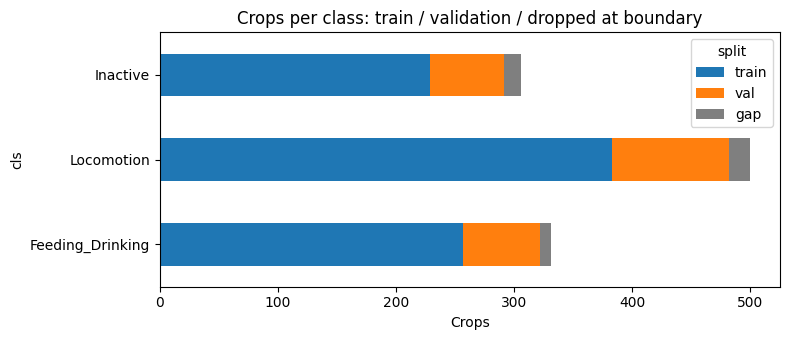

Saved: /content/drive/MyDrive/civet2/results/cc2_split.csv (1095 crops)


In [ ]:
# Input : cc1_crops.csv | Output: cc2_split.csv, cc2_split.png
CAP, VAL_FRAC, GAP, MIN_CLIP = 500, 0.2, 3, 10

crops = pd.read_csv(RESULTS / 'cc1_crops.csv')
data = crops[crops['crop_path'].notna() & crops['cls'].isin(CLASSES)].copy()
leak = [in_test_hour(cl, t) for cl, t in zip(data['clip'], data['t'])]
print('Removed (inside the test hour, data leak):', int(np.sum(leak)))
data = data[~np.array(leak)]
print('Crops per class:', data['cls'].value_counts().reindex(CLASSES).to_dict())

def cap_round_robin(df, cap):
    if len(df) <= cap:
        return df
    pools = {c: g.sample(frac=1, random_state=SEED).index.tolist()
             for c, g in df.groupby('camera')}
    keep = []
    while len(keep) < cap:
        for c in sorted(pools):
            if pools[c] and len(keep) < cap:
                keep.append(pools[c].pop())
    return df.loc[keep]

def split_clip(g):
    g = g.sort_values('t').copy()
    n = len(g)
    if n < MIN_CLIP:
        g['split'] = 'train'
        return g
    cut = int(round(n * (1 - VAL_FRAC)))
    pos = np.arange(n)
    g['split'] = np.where(pos >= cut, 'val', np.where(pos >= cut - GAP, 'gap', 'train'))
    return g

capped = pd.concat([cap_round_robin(g, CAP) for _, g in data.groupby('cls')])
rows_all = pd.concat([split_clip(g) for _, g in capped.groupby(['clip', 'cls'])])
split = rows_all[rows_all['split'] != 'gap'].reset_index(drop=True)
split.to_csv(RESULTS / 'cc2_split.csv', index=False)

tab = pd.crosstab(rows_all['cls'], rows_all['split']).reindex(
    index=CLASSES, columns=['train', 'val', 'gap'], fill_value=0)
tab['val_%'] = (tab['val'] / (tab['train'] + tab['val']) * 100).round(1)
display(tab)

ax = tab[['train', 'val', 'gap']].plot(kind='barh', stacked=True, figsize=(8, 3.5),
                                       color=['tab:blue', 'tab:orange', 'tab:gray'])
ax.invert_yaxis(); ax.set_xlabel('Crops')
plt.title('Crops per class: train / validation / dropped at boundary')
plt.tight_layout(); plt.savefig(RESULTS / 'cc2_split.png', dpi=120); plt.show()
print('Saved:', RESULTS / 'cc2_split.csv', f'({len(split)} crops)')

## Step C3: Preprocessing, Augmentation and DataLoader
Same `prep()` as the baseline; augmentation: box jitter, flip, brightness/contrast.

  cached 300/1095
  cached 600/1095
  cached 900/1095
Train: 869 crops | Val: 226 crops


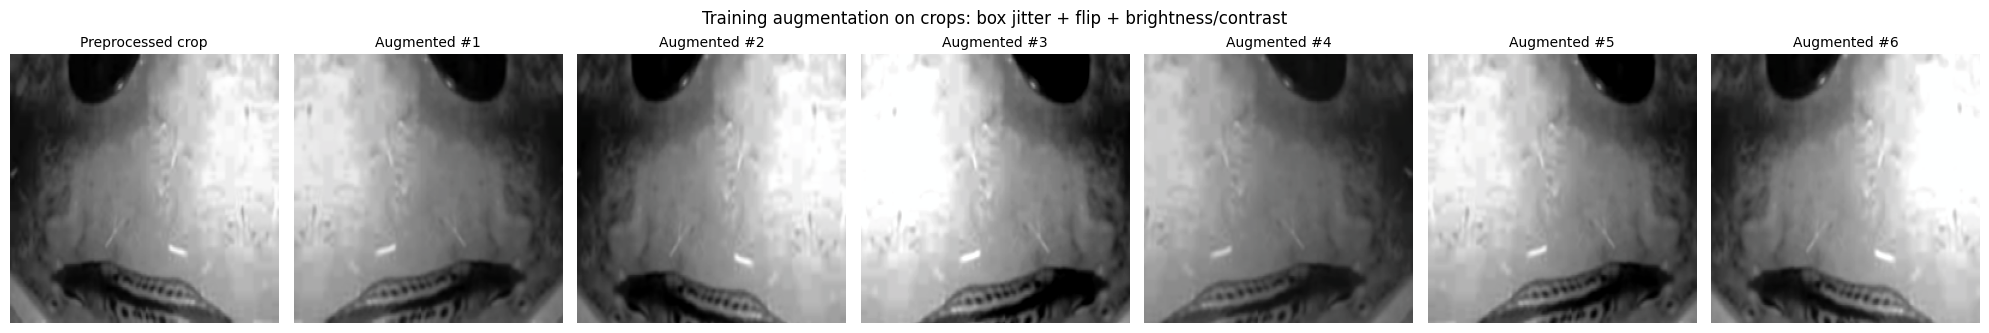

In [ ]:
# Input : cc2_split.csv | Output: /content/crop_cache/*.png, cc3_augmentation.png
from torch.utils.data import Dataset, DataLoader
BATCH = 32

CACHE = Path('/content/crop_cache')
shutil.rmtree(CACHE, ignore_errors=True)   # always rebuild: split may have changed
CACHE.mkdir()
split = pd.read_csv(RESULTS / 'cc2_split.csv')
split['cache'] = [str(CACHE / f'{i:05d}.png') for i in range(len(split))]
for k, r in enumerate(split.itertuples(), 1):
    cv2.imwrite(r.cache, prep(cv2.imread(r.crop_path)))   # same prep(): gray -> HE -> Gaussian -> 224
    if k % 300 == 0:
        print(f'  cached {k}/{len(split)}', flush=True)

train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.9, 1.1)),   # small box jitter
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(), T.Normalize(MEAN, STD)])

class CropDataset(Dataset):
    def __init__(self, df, tf):
        self.paths = df['cache'].tolist()
        self.labels = df['cls'].map(CLS2ID).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert('RGB')), self.labels[i]

train_df = split[split['split'] == 'train'].reset_index(drop=True)
val_df = split[split['split'] == 'val'].reset_index(drop=True)
train_dl = DataLoader(CropDataset(train_df, train_tf), batch_size=BATCH, shuffle=True,
                      num_workers=2, pin_memory=True)
val_dl = DataLoader(CropDataset(val_df, val_tf), batch_size=BATCH, shuffle=False,
                    num_workers=2, pin_memory=True)
train_eval_dl = DataLoader(CropDataset(train_df, val_tf), batch_size=BATCH, shuffle=False,
                           num_workers=2)
print(f'Train: {len(train_df)} crops | Val: {len(val_df)} crops')

def denorm(t):
    return (t.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)

r = train_df[train_df['cls'] == 'Locomotion'].sample(1, random_state=SEED).iloc[0]
img = Image.open(r['cache']).convert('RGB')
fig, ax = plt.subplots(1, 7, figsize=(20, 3.4))
ax[0].imshow(img); ax[0].set_title('Preprocessed crop', fontsize=10)
for k in range(1, 7):
    ax[k].imshow(denorm(train_tf(img))); ax[k].set_title(f'Augmented #{k}', fontsize=10)
for a in ax:
    a.axis('off')
plt.suptitle('Training augmentation on crops: box jitter + flip + brightness/contrast')
plt.tight_layout(); plt.savefig(RESULTS / 'cc3_augmentation.png', dpi=120); plt.show()

## Step C4: Model Training
ResNet18 (ImageNet), 3 classes, class weights, Adam 1e-4, 10 epochs, best validation macro-F1.

Class weights: {'Inactive': np.float32(1.26), 'Locomotion': np.float32(0.76), 'Feeding_Drinking': np.float32(1.13)}
Epoch  1/10 | train loss 0.396 acc 0.841 F1 0.841 | val loss 0.656 acc 0.761 F1 0.749 | 5s  <- saved (best)
Epoch  2/10 | train loss 0.157 acc 0.938 F1 0.939 | val loss 0.411 acc 0.858 F1 0.852 | 5s  <- saved (best)
Epoch  3/10 | train loss 0.092 acc 0.968 F1 0.969 | val loss 0.282 acc 0.898 F1 0.895 | 5s  <- saved (best)
Epoch  4/10 | train loss 0.052 acc 0.982 F1 0.982 | val loss 0.350 acc 0.889 F1 0.881 | 5s
Epoch  5/10 | train loss 0.028 acc 0.995 F1 0.995 | val loss 0.473 acc 0.876 F1 0.866 | 6s
Epoch  6/10 | train loss 0.021 acc 0.997 F1 0.997 | val loss 0.366 acc 0.898 F1 0.894 | 6s
Epoch  7/10 | train loss 0.017 acc 0.998 F1 0.998 | val loss 0.346 acc 0.907 F1 0.899 | 5s  <- saved (best)
Epoch  8/10 | train loss 0.029 acc 0.988 F1 0.989 | val loss 0.494 acc 0.867 F1 0.864 | 5s
Epoch  9/10 | train loss 0.015 acc 0.998 F1 0.998 | val loss 0.468 acc 0.889 F1 0.884 | 

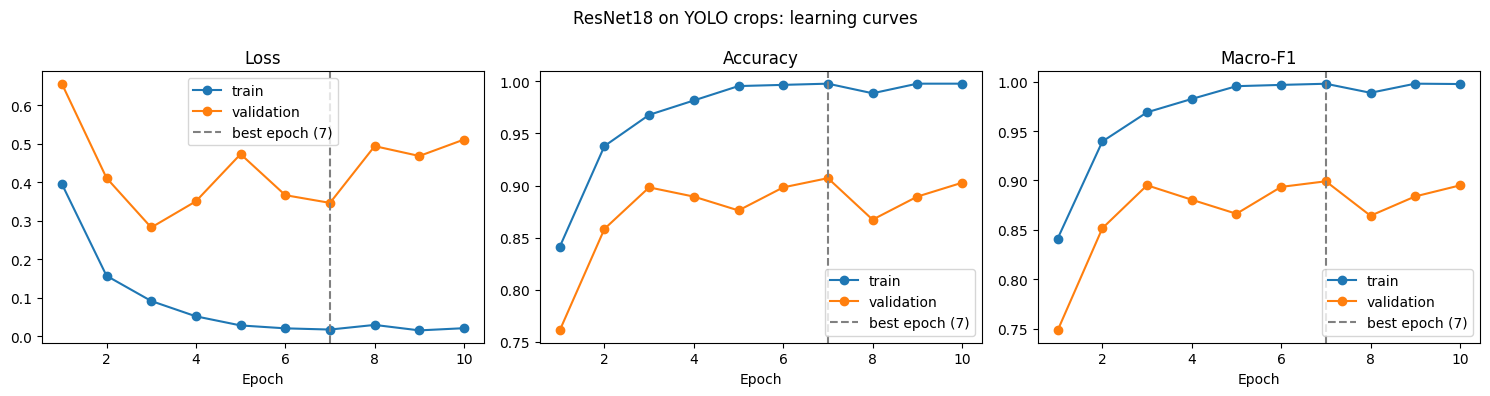

In [ ]:
# Needs: C3 | Output: models/resnet18_crop.pt, cc4_history.csv, cc4_curves.png
import time
from sklearn.metrics import f1_score

EPOCHS, LR = 10, 1e-4
torch.manual_seed(SEED)
model = build_model()
counts = train_df['cls'].value_counts().reindex(CLASSES).values
weights = torch.tensor(counts.sum() / (len(CLASSES) * counts), dtype=torch.float32)
print('Class weights:', dict(zip(CLASSES, weights.numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=weights.to(device))
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def run_epoch(dl, train):
    model.train(train)
    total, preds, labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(y)
            preds += out.argmax(1).tolist(); labels += y.tolist()
    preds, labels = np.array(preds), np.array(labels)
    return total / len(labels), (preds == labels).mean(), f1_score(labels, preds, average='macro')

history, best_f1 = [], -1
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    tr = run_epoch(train_dl, True)
    va = run_epoch(val_dl, False)
    history.append(dict(epoch=ep, train_loss=tr[0], val_loss=va[0], train_acc=tr[1],
                        val_acc=va[1], train_f1=tr[2], val_f1=va[2]))
    mark = ''
    if va[2] > best_f1:
        best_f1, best_ep = va[2], ep
        torch.save({'state_dict': model.state_dict(), 'classes': CLASSES, 'img_size': IMG_SIZE,
                    'mean': MEAN, 'std': STD, 'margin': MARGIN, 'epoch': ep,
                    'val_f1': float(va[2])}, MODELS / 'resnet18_crop.pt')
        mark = '  <- saved (best)'
    print(f'Epoch {ep:2}/{EPOCHS} | train loss {tr[0]:.3f} acc {tr[1]:.3f} F1 {tr[2]:.3f} | '
          f'val loss {va[0]:.3f} acc {va[1]:.3f} F1 {va[2]:.3f} | {time.time() - t0:.0f}s{mark}')

hist = pd.DataFrame(history)
hist.to_csv(RESULTS / 'cc4_history.csv', index=False)
print(f'\nBest epoch {best_ep} | val macro-F1 {best_f1:.3f} | saved to {MODELS / "resnet18_crop.pt"}')

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, key) in zip(ax, [('Loss', 'loss'), ('Accuracy', 'acc'), ('Macro-F1', 'f1')]):
    a.plot(hist['epoch'], hist[f'train_{key}'], 'o-', label='train')
    a.plot(hist['epoch'], hist[f'val_{key}'], 'o-', label='validation')
    a.axvline(best_ep, color='gray', ls='--', label=f'best epoch ({best_ep})')
    a.set_title(name); a.set_xlabel('Epoch'); a.legend()
plt.suptitle('ResNet18 on YOLO crops: learning curves')
plt.tight_layout(); plt.savefig(RESULTS / 'cc4_curves.png', dpi=120); plt.show()

## Step C5: Validation Results and Thresholds
Thresholds are set on training/validation data only (never on the test hour).

                  precision    recall  f1-score   support

        Inactive      0.978     0.726     0.833        62
      Locomotion      0.881     0.970     0.923        99
Feeding_Drinking      0.901     0.985     0.941        65

        accuracy                          0.907       226
       macro avg      0.920     0.893     0.899       226
    weighted avg      0.913     0.907     0.904       226



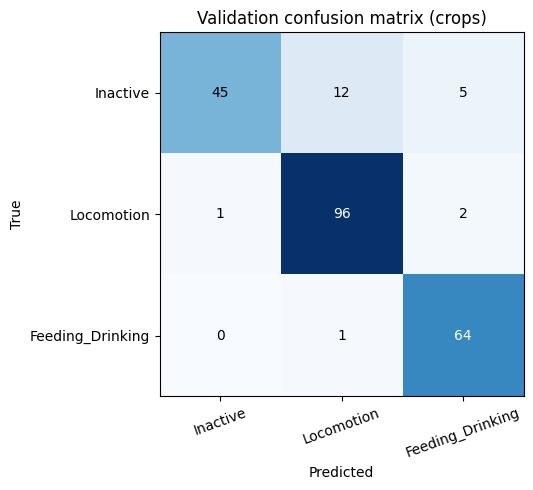

Feature-distance threshold (95th pct of correct val): 0.245 -> 7.1% of val would become Other
Training pairs: {'Inactive': 193, 'Locomotion': 160}
Move threshold: 0.149 body lengths in ~5 s (balanced accuracy on training pairs 0.920)


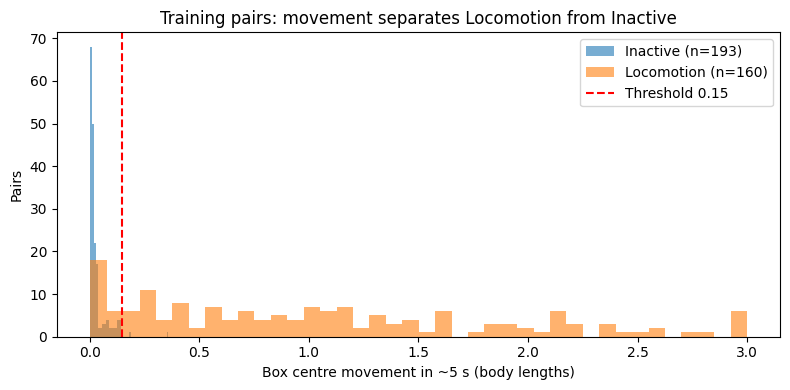

In-place motion threshold (95th pct of Inactive pairs): 4.65


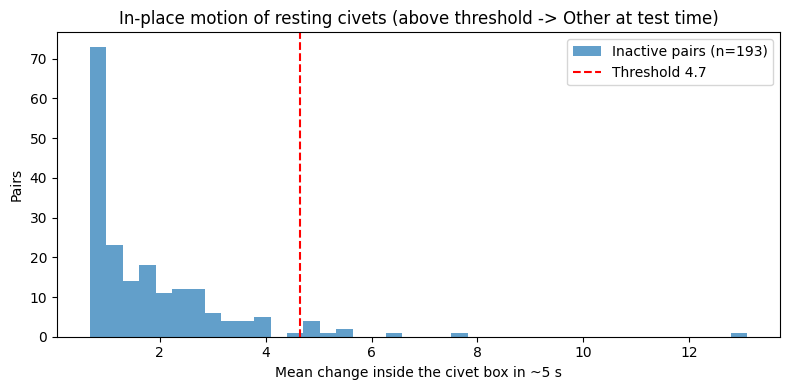

Saved thresholds: {'dist_thr': 0.24510018527507782, 'move_thr': 0.149198852506608, 'motion_thr': 4.654247665405267}


In [ ]:
# ===== Cell C5: Validation results and thresholds (set on training/validation data only) =====
# Needs: C3 | Output: cc5_report.txt, cc5_confusion.png, cc5_move_hist.png, cc5_motion_hist.png,
#                     cc5_thresholds.json; thresholds saved into models/resnet18_crop.pt
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score

ckpt = torch.load(MODELS / 'resnet18_crop.pt', map_location=device, weights_only=False)
model = build_model(); model.load_state_dict(ckpt['state_dict']); model.eval()

def embed(dl):
    feats, probs = [], []
    with torch.no_grad():
        for x, _ in dl:
            f, out = forward_feat(model, x.to(device))
            feats.append(F.normalize(f, dim=1).cpu().numpy())
            probs.append(F.softmax(out, 1).cpu().numpy())
    return np.concatenate(feats), np.concatenate(probs)

# ---------- 1. Classification report ----------
f_val, p_val = embed(val_dl)
pred, labels = p_val.argmax(1), val_df['cls'].map(CLS2ID).values
report = classification_report(labels, pred, target_names=CLASSES, digits=3)
print(report)

cm = confusion_matrix(labels, pred, labels=range(len(CLASSES)))
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap='Blues')
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xticks(range(len(CLASSES)), CLASSES, rotation=20); plt.yticks(range(len(CLASSES)), CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Validation confusion matrix (crops)')
plt.tight_layout(); plt.savefig(RESULTS / 'cc5_confusion.png', dpi=120); plt.show()

# ---------- 2. Other detector A: feature distance to the class mean ----------
f_tr, _ = embed(train_eval_dl)
y_tr = train_df['cls'].map(CLS2ID).values
class_means = np.stack([f_tr[y_tr == k].mean(0) for k in range(len(CLASSES))])
class_means /= np.linalg.norm(class_means, axis=1, keepdims=True)
dist_val = 1 - (f_val * class_means[pred]).sum(1)          # cosine distance to predicted class
DIST_THR = float(np.percentile(dist_val[pred == labels], 95))
print(f'Feature-distance threshold (95th pct of correct val): {DIST_THR:.3f} '
      f'-> {(dist_val > DIST_THR).mean():.1%} of val would become Other')

# ---------- 3. Training frame pairs (~5 s apart, same clip and class) ----------
crops = pd.read_csv(RESULTS / 'cc1_crops.csv')
c = crops[crops['crop_path'].notna() & crops['cls'].isin(['Inactive', 'Locomotion'])]
c = c[[not in_test_hour(cl, t) for cl, t in zip(c['clip'], c['t'])]]
c = c.sort_values(['clip', 't'])
nxt = c.groupby('clip').shift(-1)
ok = (nxt['cls'] == c['cls']) & (nxt['t'] - c['t']).between(*PAIR_GAP)
pairs = c[ok].copy()
for col in ['path', 'x1', 'y1', 'x2', 'y2']:
    pairs[f'{col}_n'] = nxt.loc[ok, col]
cx0, cy0 = (pairs['x1'] + pairs['x2']) / 2, (pairs['y1'] + pairs['y2']) / 2
cx1, cy1 = (pairs['x1_n'] + pairs['x2_n']) / 2, (pairs['y1_n'] + pairs['y2_n']) / 2
body = np.maximum(pairs['x2'] - pairs['x1'], pairs['y2'] - pairs['y1'])
pairs['move'] = np.hypot(cx1 - cx0, cy1 - cy0) / body
print('Training pairs:', pairs['cls'].value_counts().to_dict())

# Position rule threshold: best balanced accuracy on training pairs
y_pair = (pairs['cls'] == 'Locomotion').astype(int).values
grid = np.quantile(pairs['move'], np.linspace(0.02, 0.98, 97))
scores = [balanced_accuracy_score(y_pair, (pairs['move'] > g).astype(int)) for g in grid]
MOVE_THR = float(grid[int(np.argmax(scores))])
print(f'Move threshold: {MOVE_THR:.3f} body lengths in ~5 s '
      f'(balanced accuracy on training pairs {max(scores):.3f})')

plt.figure(figsize=(8, 4))
for lab, col in [('Inactive', 'tab:blue'), ('Locomotion', 'tab:orange')]:
    plt.hist(pairs.loc[pairs['cls'] == lab, 'move'].clip(upper=3), bins=40, alpha=0.6,
             color=col, label=f'{lab} (n={(pairs["cls"] == lab).sum()})')
plt.axvline(MOVE_THR, color='red', ls='--', label=f'Threshold {MOVE_THR:.2f}')
plt.xlabel('Box centre movement in ~5 s (body lengths)'); plt.ylabel('Pairs')
plt.title('Training pairs: movement separates Locomotion from Inactive'); plt.legend()
plt.tight_layout(); plt.savefig(RESULTS / 'cc5_move_hist.png', dpi=120); plt.show()

# ---------- 4. Other detector B: in-place motion while Inactive ----------
inact = pairs[pairs['cls'] == 'Inactive']
energy = []
for r in inact.itertuples():
    a, b = cv2.imread(r.path), cv2.imread(r.path_n)
    _, region = crop_square(a, (r.x1, r.y1, r.x2, r.y2))
    energy.append(motion_energy(a, b, region))
MOTION_THR = float(np.percentile(energy, 95))
print(f'In-place motion threshold (95th pct of Inactive pairs): {MOTION_THR:.2f}')

plt.figure(figsize=(8, 4))
plt.hist(energy, bins=40, color='tab:blue', alpha=0.7, label=f'Inactive pairs (n={len(energy)})')
plt.axvline(MOTION_THR, color='red', ls='--', label=f'Threshold {MOTION_THR:.1f}')
plt.xlabel('Mean change inside the civet box in ~5 s'); plt.ylabel('Pairs')
plt.title('In-place motion of resting civets (above threshold -> Other at test time)')
plt.legend(); plt.tight_layout(); plt.savefig(RESULTS / 'cc5_motion_hist.png', dpi=120); plt.show()

# ---------- Save ----------
thr = {'dist_thr': DIST_THR, 'move_thr': MOVE_THR, 'motion_thr': MOTION_THR}
ckpt.update(thr); ckpt['class_means'] = class_means
torch.save(ckpt, MODELS / 'resnet18_crop.pt')
json.dump(thr, open(RESULTS / 'cc5_thresholds.json', 'w'), indent=1)
with open(RESULTS / 'cc5_report.txt', 'w') as f:
    f.write(f"Epoch {ckpt['epoch']}\n\n{report}\n{json.dumps(thr, indent=1)}\n")
print('Saved thresholds:', thr)

## Step C6: Test Hour — YOLO Crop + ResNet
Every second of the 4 test clips; YOLO gaps ≤ 5 s keep the last room and behavior.

In [6]:
!pip install -q ultralytics

In [7]:
# Output: cc6_test_cam.csv (camera x second), cc6_timeline.csv (4 cameras combined)
from ultralytics import YOLO
TEST = BASE / 'test'
T_START, T_END = 0, 24 * 3600 - 1   # whole clips (no fixed window)

ckpt = torch.load(MODELS / 'resnet18_crop.pt', map_location=device, weights_only=False)
model = build_model(); model.load_state_dict(ckpt['state_dict']); model.eval()
MEANS = ckpt['class_means']
DIST_THR, MOVE_THR, MOTION_THR = ckpt['dist_thr'], ckpt['move_thr'], ckpt['motion_thr']
yolo = YOLO(str(find_yolo()))

def clip_start(p):
    d = re.search(r'_(\d{14})', p.stem).group(1)
    sec = int(d[8:10]) * 3600 + int(d[10:12]) * 60 + int(d[12:14])
    cut = re.search(r'-(\d\d)\.(\d\d)\.(\d\d)\.\d+-', p.stem)
    if cut:
        h, m, s = map(int, cut.groups()); sec += h * 3600 + m * 60 + s
    return sec

def extract_frames(video, start, dur, out_dir):
    shutil.rmtree(out_dir, ignore_errors=True); out_dir.mkdir(parents=True)
    subprocess.run(['ffmpeg', '-v', 'error', '-ss', str(start), '-i', str(video), '-t', str(dur),
                    '-vf', 'fps=1', '-q:v', '2', str(out_dir / '%05d.jpg')])
    return sorted(out_dir.glob('*.jpg'))

def decide(r):
    if not r['found']:
        return 'Not_visible'
    if r['dist'] > DIST_THR:
        return 'Other'                                   # unlike any trained behavior
    beh = r['beh']
    if beh in ('Inactive', 'Locomotion') and pd.notna(r['move']):
        beh = 'Locomotion' if r['move'] > MOVE_THR else 'Inactive'
    if beh == 'Inactive' and pd.notna(r['motion']) and r['motion'] > MOTION_THR:
        return 'Other'                                   # active in place (e.g. grooming)
    return beh

all_rows = []
for vid in sorted((TEST / 'hour').glob('*.mp4')):
    cam, t0 = vid.name[:3], clip_start(vid)
    local = Path('/content/video') / vid.name
    local.parent.mkdir(exist_ok=True)
    print(f'{cam}: copying and extracting 1 frame/s ...', flush=True)
    shutil.copy(vid, local)
    s_from = max(T_START - t0, 0)
    jpgs = extract_frames(local, s_from, T_END - t0 - s_from + 1, Path('/content/frames') / cam)
    local.unlink()
    secs = [t0 + s_from + k for k in range(len(jpgs))]

    rows, batch, meta = [], [], []
    def flush():
        with torch.no_grad():
            f, out = forward_feat(model, torch.stack(batch).to(device))
            f = F.normalize(f, dim=1).cpu().numpy(); p = F.softmax(out, 1).cpu().numpy()
        for (i, box, conf, region), fi, pi in zip(meta, f, p):
            k = int(pi.argmax())
            rows[i].update(found=True, yolo_conf=conf, x1=box[0], y1=box[1], x2=box[2], y2=box[3],
                           l=region[0], t=region[1], r=region[2], b=region[3],
                           beh=CLASSES[k], cls_conf=float(pi[k]),
                           dist=float(1 - fi @ MEANS[k]),
                           **{f'p_{c}': float(v) for c, v in zip(CLASSES, pi)})
        batch.clear(); meta.clear()

    for i, (jp, sec) in enumerate(zip(jpgs, secs)):
        img = cv2.imread(str(jp))
        rows.append({'camera': cam, 'sec': sec, 'time': fmt(sec), 'frame': str(jp), 'found': False})
        box, conf = best_box(yolo.predict(img, conf=YOLO_CONF, verbose=False)[0])
        if box is not None:
            crop, region = crop_square(img, box)
            batch.append(val_tf(Image.fromarray(prep(crop))))
            meta.append((i, box, conf, region))
            if len(batch) == 64:
                flush()
        if (i + 1) % 300 == 0:
            print(f'   {fmt(sec)}', flush=True)
    if batch:
        flush()
    df = pd.DataFrame(rows)

    # movement (body lengths) and in-place motion between t and t+5 (or t-5)
    df = df.set_index('sec')
    body = np.maximum(df['x2'] - df['x1'], df['y2'] - df['y1'])
    cx, cy = (df['x1'] + df['x2']) / 2, (df['y1'] + df['y2']) / 2
    moves, motions = [], []
    for s in df.index:
        mv, mo = np.nan, np.nan
        if df.at[s, 'found']:
            for o in (s + SHIFT, s - SHIFT):
                if o in df.index and df.at[o, 'found']:
                    mv = np.hypot(cx[o] - cx[s], cy[o] - cy[s]) / body[s]
                    region = tuple(int(df.at[s, k]) for k in 'ltrb')
                    mo = motion_energy(cv2.imread(df.at[s, 'frame']), cv2.imread(df.at[o, 'frame']), region)
                    break
        moves.append(mv); motions.append(mo)
    df['move'], df['motion'] = moves, motions
    df = df.reset_index()
    df['label'] = [decide(r) for _, r in df.iterrows()]
    shutil.rmtree(Path('/content/frames') / cam, ignore_errors=True)
    print(f'   {cam}: {len(df)} s, detected {df["found"].mean():.0%}', flush=True)
    all_rows.append(df.drop(columns='frame'))

cam_df = pd.concat(all_rows, ignore_index=True)
cam_df.to_csv(RESULTS / 'cc6_test_cam.csv', index=False)
display(pd.crosstab(cam_df['camera'], cam_df['label']))

# ---------- Combine 4 cameras ----------
# Seen: camera with the most confident YOLO box.
# Not seen <= GAP_FILL_S s: short detection gap -> keep last room and behavior.
# Not seen longer: keep last room, civet counted as Inactive (in box / resting out of view).
GAP_FILL_S = 5
out, last_room, last_beh, last_seen = [], 'A02', 'Inactive', None
for s, g in cam_df.groupby('sec'):
    vis = g[g['found']]
    if len(vis):
        r = vis.loc[vis['yolo_conf'].idxmax()]
        last_room, last_beh, last_seen = r['camera'], r['label'], s
        out.append((s, last_room, last_beh, len(vis)))
    elif last_seen is not None and s - last_seen <= GAP_FILL_S:
        out.append((s, last_room, last_beh, 0))
    else:
        out.append((s, last_room, 'Inactive', 0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 151MB/s]


A01: copying and extracting 1 frame/s ...
   00:04:59
   00:09:59
   00:14:59
   00:19:59
   00:24:59
   00:29:59
   00:34:59
   00:39:59
   00:44:59
   00:49:59
   00:54:59
   00:59:59
   01:04:59
   01:09:59
   A01: 4432 s, detected 6%
A02: copying and extracting 1 frame/s ...
   00:04:59
   00:09:59
   00:14:59
   00:19:59
   00:24:59
   00:29:59
   00:34:59
   00:39:59
   00:44:59
   00:49:59
   00:54:59
   00:59:59
   A02: 3618 s, detected 15%
A03: copying and extracting 1 frame/s ...
   00:04:59
   00:09:59
   00:14:59
   00:19:59
   00:24:59
   00:29:59
   00:34:59
   00:39:59
   00:44:59
   00:49:59
   00:54:59
   00:59:59
   A03: 3609 s, detected 13%
A04: copying and extracting 1 frame/s ...
   00:04:59
   00:09:59
   00:14:59
   00:19:59
   00:24:59
   00:29:59
   00:34:59
   00:39:59
   00:44:59
   00:49:59
   00:54:59
   00:59:59
   A04: 3602 s, detected 12%


label,Feeding_Drinking,Inactive,Locomotion,Not_visible,Other
camera,,,,,
A01,0,60,189,4168,15
A02,0,326,176,3092,24
A03,122,24,172,3127,164
A04,9,160,209,3156,68


In [19]:
# ===== Cell C6b: Combine 4 cameras from the saved per-camera results (no video needed) =====
# Input : cc6_test_cam.csv | Output: cc6_timeline.csv (common window of all 4 cameras)
cam_df = pd.read_csv(RESULTS / 'cc6_test_cam.csv')
cam_df['found'] = cam_df['found'].astype(bool)

# Score only where all 4 cameras have video (A01 is longer than the others)
t_last = int(cam_df.groupby('camera')['sec'].max().min())
cam_df = cam_df[cam_df['sec'] <= t_last]

# Seen: camera with the most confident YOLO box.
# Not seen <= GAP_FILL_S s: short detection gap -> keep last room and behavior.
# Not seen longer: keep last room, civet counted as Inactive (in box / resting out of view).
GAP_FILL_S = 5
out, last_room, last_beh, last_seen = [], 'A02', 'Inactive', None
for s, g in cam_df.groupby('sec'):
    vis = g[g['found']]
    if len(vis):
        r = vis.loc[vis['yolo_conf'].idxmax()]
        last_room, last_beh, last_seen = r['camera'], r['label'], s
        out.append((s, last_room, last_beh, len(vis)))
    elif last_seen is not None and s - last_seen <= GAP_FILL_S:
        out.append((s, last_room, last_beh, 0))
    else:
        out.append((s, last_room, 'Inactive', 0))

tl6 = pd.DataFrame(out, columns=['sec', 'room', 'beh', 'n_cams'])
tl6.to_csv(RESULTS / 'cc6_timeline.csv', index=False)
print(f'cc6_timeline.csv: {fmt(tl6["sec"].min())} - {fmt(tl6["sec"].max())} ({len(tl6)} s)')

cc6_timeline.csv: 00:00:00 - 01:00:01 (3602 s)


## Step C7: Evaluation and Comparison
Compared with the previous system and the always-Active baseline.

Evaluation window: 00:00:00 - 01:00:01 (3602 s)
Active/Inactive counts ground-truth Other (Grooming, Urination, ...) as Active.


system,ResNet + YOLO room (previous),YOLO crop + ResNet (new),Baseline: always Active,Ground truth
scored_window,00:35:39-01:00:01,00:00:00-01:00:01,NaN,NaN
behavior_acc,0.534,0.823,NaN,NaN
behavior_acc_trained_only,0.68,0.893,NaN,NaN
active_inactive_acc,0.602,0.865,0.315,NaN
active_inactive_balanced,0.654,0.806,0.5,NaN
inactive_recall,0.743,0.966,0.0,NaN
active_recall,0.564,0.646,1.0,NaN
other_recall,0.0,0.076,NaN,NaN
false_other_rate,0.032,0.035,NaN,NaN
room_acc,0.886,0.952,NaN,NaN


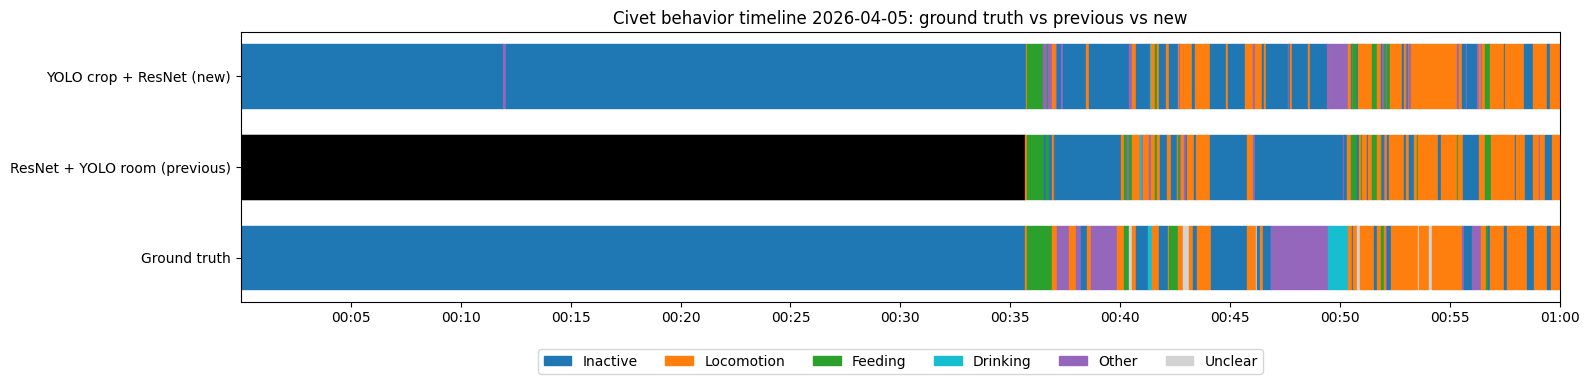

,system_s,ground_truth_s,system_%,ground_truth_%
Inactive,2750,2435,76.3,67.6
Locomotion,599,631,16.6,17.5
Feeding,103,119,2.9,3.3
Drinking,5,66,0.1,1.8
Other,145,304,4.0,8.4
Unclear,0,47,0.0,1.3


Saved: /content/drive/MyDrive/civet2/results/cc7_observation_sheet.xlsx


In [20]:
# Input : cc6_timeline.csv, test/hour_labels.csv (ground truth),
#         c9_yolo_timeline.csv (previous system)
# Output: cc7_comparison.csv, cc7_timeline.png, cc7_observation_sheet.xlsx
from sklearn.metrics import balanced_accuracy_score
DATE = '2026-04-05'
SMOOTH_S, MERGE_GAP_S, MIN_EVENT_S = 5, 60, 5
ROOM = {'A01': 'A01 empty room', 'A02': 'A02 sleeping box',
        'A03': 'A03 food tray', 'A04': 'A04 water tray'}

# Ground truth from the hand labels for the whole clip.
# Seconds with no label = civet in the sleeping box (A02), as recorded by the labeler.
hl = pd.read_csv(BASE / 'test' / 'hour_labels.csv')
GT_MAP = {'Resting': 'Inactive', 'Sitting': 'Inactive', 'Standing': 'Inactive', 'In_box': 'Inactive',
          'Locomotion': 'Locomotion', 'Feeding': 'Feeding_Drinking', 'Drinking': 'Feeding_Drinking',
          'Other': 'Unknown', 'Unclear': None}
gt_m = {}
for r in hl.itertuples():
    room = 'A02' if r.behavior == 'In_box' else r.camera
    for s in range(hms(r.start), hms(r.end) + 1):
        gt_m[s] = (GT_MAP.get(r.behavior), room)
gt = pd.DataFrame({'sec': pd.read_csv(RESULTS / 'cc6_timeline.csv')['sec']})
gt['gt'] = [gt_m.get(s, ('Inactive', 'A02'))[0] for s in gt['sec']]
gt['gt_room'] = [gt_m.get(s, ('Inactive', 'A02'))[1] for s in gt['sec']]
prev = pd.read_csv(RESULTS / 'c9_yolo_timeline.csv')[['sec', 'room_yolo', 'beh_yolo']]
new = pd.read_csv(RESULTS / 'cc6_timeline.csv')[['sec', 'room', 'beh']]
tl = gt.merge(prev, on='sec', how='left').merge(new, on='sec')   # previous system covers 00:35-01:00 only
tl = tl.sort_values('sec').reset_index(drop=True)
tl['gt'] = tl['gt'].replace({'Unknown': 'Other'})       # ground-truth other behaviors
tl['beh_yolo'] = tl['beh_yolo'].replace({'Unknown': 'Other'})
first, last = fmt(tl['sec'].iloc[0]), fmt(tl['sec'].iloc[-1])
print(f'Evaluation window: {first} - {last} ({len(tl)} s)')

def smooth(values, k=SMOOTH_S):
    v, h = list(values), k // 2
    return [Counter(v[max(0, i - h): i + h + 1]).most_common(1)[0][0]
            for i in range(len(v))]

def split_fd(beh, room):
    if beh != 'Feeding_Drinking':
        return beh
    return 'Drinking' if room == 'A04' else 'Feeding'

def status(beh):
    if beh == 'Inactive':
        return 'Inactive'
    if beh in ('Locomotion', 'Feeding', 'Drinking', 'Other'):
        return 'Active'
    return beh

def events(secs, labels, target):
    on = [s for s, l in zip(secs, labels) if l == target]
    runs = []
    for s in on:
        if runs and s - runs[-1][1] <= 1:
            runs[-1][1] = s
        else:
            runs.append([s, s])
    merged = []
    for r in runs:
        if merged and r[0] - merged[-1][1] - 1 < MERGE_GAP_S:
            merged[-1][1] = r[1]
        else:
            merged.append(r)
    return [(a, b) for a, b in merged if b - a + 1 >= MIN_EVENT_S]

def recall(p, y, label):
    return round(((p == label) & (y == label)).sum() / (y == label).sum(), 3)

tl['gt_beh'] = [split_fd(b, r) if isinstance(b, str) else 'Unclear'
                for b, r in zip(tl['gt'], tl['gt_room'])]
tl['gt_status'] = tl['gt_beh'].map(status)
ok = tl['gt_beh'] != 'Unclear'
trained = ok & tl['gt_beh'].isin(['Inactive', 'Locomotion', 'Feeding', 'Drinking'])
ai_mask = ok & tl['gt_status'].isin(['Active', 'Inactive'])
is_other = tl['gt_beh'] == 'Other'

SYSTEMS = {'ResNet + YOLO room (previous)': ('room_yolo', 'beh_yolo'),
           'YOLO crop + ResNet (new)': ('room', 'beh')}
out, rows = {}, []
for name, (rc, bc) in SYSTEMS.items():
    has = tl[bc].notna()                       # score each system only where it has predictions
    room = smooth(tl[rc])
    beh = [split_fd(b, r) for b, r in zip(smooth(tl[bc]), room)]
    d = pd.DataFrame({'sec': tl['sec'], 'room': room, 'beh': beh})
    d['status'] = d['beh'].map(status)
    out[name] = d
    ok_s, tr_s, ai_s, ot_s = ok & has, trained & has, ai_mask & has, is_other & has
    y, p = tl.loc[ai_s, 'gt_status'], d.loc[ai_s, 'status']
    acc_all = (d.loc[ok_s, 'beh'] == tl.loc[ok_s, 'gt_beh']).mean()
    acc_tr = (d.loc[tr_s, 'beh'] == tl.loc[tr_s, 'gt_beh']).mean()
    rows.append({
        'system': name,
        'scored_window': f"{fmt(tl.loc[has, 'sec'].min())}-{fmt(tl.loc[has, 'sec'].max())}",
        'behavior_acc': round(acc_all, 3),
        'behavior_acc_trained_only': round(acc_tr, 3),
        'active_inactive_acc': round((y == p).mean(), 3),
        'active_inactive_balanced': round(balanced_accuracy_score(y, p), 3),
        'inactive_recall': recall(p, y, 'Inactive'),
        'active_recall': recall(p, y, 'Active'),
        'other_recall': round((d.loc[ot_s, 'beh'] == 'Other').mean(), 3),
        'false_other_rate': round((d.loc[tr_s, 'beh'] == 'Other').mean(), 3),
        'room_acc': round((d.loc[ok_s, 'room'] == tl.loc[ok_s, 'gt_room']).mean(), 3),
        'feeding_events': len(events(d.loc[has, 'sec'], d.loc[has, 'beh'], 'Feeding')),
        'drinking_events': len(events(d.loc[has, 'sec'], d.loc[has, 'beh'], 'Drinking'))})

y = tl.loc[ai_mask, 'gt_status']
rows.append({'system': 'Baseline: always Active',
             'active_inactive_acc': round((y == 'Active').mean(), 3),
             'active_inactive_balanced': 0.5,
             'inactive_recall': 0.0, 'active_recall': 1.0})
rows.append({'system': 'Ground truth',
             'feeding_events': len(events(tl['sec'], tl['gt_beh'], 'Feeding')),
             'drinking_events': len(events(tl['sec'], tl['gt_beh'], 'Drinking'))})
comp = pd.DataFrame(rows)
comp.to_csv(RESULTS / 'cc7_comparison.csv', index=False)
print('Active/Inactive counts ground-truth Other (Grooming, Urination, ...) as Active.')
display(comp.set_index('system').T)

# ---------- Timeline figure ----------
COL = {'Inactive': 'tab:blue', 'Locomotion': 'tab:orange', 'Feeding': 'tab:green',
       'Drinking': 'tab:cyan', 'Other': 'tab:purple', 'Unclear': 'lightgray'}

def bars(labels):
    v, res, start = list(labels), [], 0
    for i in range(1, len(v) + 1):
        if i == len(v) or v[i] != v[start]:
            res.append((tl['sec'].iloc[start], i - start, v[start]))
            start = i
    return res

lines = [('Ground truth', tl['gt_beh'])] + [(n, out[n]['beh']) for n in SYSTEMS]
fig, ax = plt.subplots(figsize=(16, 4))
for yy, (name, labels) in enumerate(lines):
    for x0, w, lab in bars(labels):
        ax.broken_barh([(x0, w)], (yy - 0.35, 0.7), color=COL.get(lab, 'black'))
ax.set_yticks(range(len(lines)), [l[0] for l in lines])
t0, t1 = tl['sec'].iloc[0], tl['sec'].iloc[-1]
ticks = list(range(t0 // 300 * 300 + 300, t1, 300))
ax.set_xticks(ticks, [fmt(t)[:5] for t in ticks])
ax.set_xlim(t0, t1)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()]
ax.legend(handles, COL.keys(), ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.15))
ax.set_title(f'Civet behavior timeline {DATE}: ground truth vs previous vs new')
plt.tight_layout()
plt.savefig(RESULTS / 'cc7_timeline.png', dpi=120)
plt.show()

# ---------- Observation sheet for the new system ----------
d = out['YOLO crop + ResNet (new)'].copy()
d['gt_beh'] = tl['gt_beh']
ev_rows = []
for who, labels in [('System', d['beh']), ('Ground truth', tl['gt_beh'])]:
    for target in ['Feeding', 'Drinking']:
        for a, b in events(tl['sec'], labels, target):
            ev_rows.append({'source': who, 'behavior': target,
                            'start': fmt(a), 'end': fmt(b),
                            'duration_s': b - a + 1, 'start_sec': a})
ev_cols = ['source', 'behavior', 'start', 'end', 'duration_s', 'start_sec']
ev = pd.DataFrame(ev_rows, columns=ev_cols)

d['minute'] = d['sec'] // 60 * 60
minute_rows = []
for m, g in d.groupby('minute'):
    st = ev[(ev['source'] == 'System') & (ev['start_sec'] // 60 * 60 == m)]
    minute_rows.append({
        'date': DATE, 'time': fmt(m)[:5],
        'room': ROOM[g['room'].mode()[0]],
        'behavior': g['beh'].mode()[0],
        'status': g['status'].mode()[0],
        'active_s': int((g['status'] == 'Active').sum()),
        'inactive_s': int((g['status'] == 'Inactive').sum()),
        'feeding_events': int((st['behavior'] == 'Feeding').sum()),
        'drinking_events': int((st['behavior'] == 'Drinking').sum()),
        'gt_behavior': g['gt_beh'].mode()[0]})

BEH = ['Inactive', 'Locomotion', 'Feeding', 'Drinking', 'Other', 'Unclear']
sys_s = d['beh'].value_counts().reindex(BEH, fill_value=0)
gt_s = tl['gt_beh'].value_counts().reindex(BEH, fill_value=0)
beh_sum = pd.DataFrame({'system_s': sys_s, 'ground_truth_s': gt_s})
beh_sum['system_%'] = (beh_sum['system_s'] / len(d) * 100).round(1)
beh_sum['ground_truth_%'] = (beh_sum['ground_truth_s'] / len(d) * 100).round(1)
display(beh_sum)

xlsx = RESULTS / 'cc7_observation_sheet.xlsx'
with pd.ExcelWriter(xlsx) as w:
    pd.DataFrame(minute_rows).to_excel(w, sheet_name='Timeline', index=False)
    beh_sum.to_excel(w, sheet_name='Behavior summary')
    ev.drop(columns='start_sec').to_excel(w, sheet_name='Events', index=False)
    comp.to_excel(w, sheet_name='Comparison', index=False)
print('Saved:', xlsx)

## Step C8: Ablation
Each post-processing rule switched on/off on the same predictions. The distance and motion Other detectors did not help, so the final system uses the move rule only.

In [21]:
# ===== Cell C8: Ablation — which post-processing rules help? =====
# Needs: C0 and C7 in this session | Input: cc6_test_cam.csv | Output: cc8_ablation.csv
cam_df = pd.read_csv(RESULTS / 'cc6_test_cam.csv')
ck = torch.load(MODELS / 'resnet18_crop.pt', map_location='cpu', weights_only=False)
DIST_THR, MOVE_THR, MOTION_THR = ck['dist_thr'], ck['move_thr'], ck['motion_thr']

def label(r, use_dist, use_move, use_motion):
    if not r['found']:
        return 'Not_visible'
    if use_dist and r['dist'] > DIST_THR:
        return 'Other'
    beh = r['beh']
    if use_move and beh in ('Inactive', 'Locomotion') and pd.notna(r['move']):
        beh = 'Locomotion' if r['move'] > MOVE_THR else 'Inactive'
    if use_motion and beh == 'Inactive' and pd.notna(r['motion']):
        if r['motion'] > MOTION_THR:
            return 'Other'
    return beh

def combine(cdf):
    """Same rule as C6: best YOLO box; gap <= 5 s keeps last; else last room + Inactive."""
    res, room, beh, seen = [], 'A02', 'Inactive', None
    for s, g in cdf.groupby('sec'):
        vis = g[g['found']]
        if len(vis):
            r = vis.loc[vis['yolo_conf'].idxmax()]
            room, beh, seen = r['camera'], r['lab'], s
            res.append((s, room, beh))
        elif seen is not None and s - seen <= 5:
            res.append((s, room, beh))
        else:
            res.append((s, room, 'Inactive'))
    return pd.DataFrame(res, columns=['sec', 'room', 'beh'])

def score(name, comb):
    comb = tl[['sec']].merge(comb, on='sec', how='left')
    room = smooth(comb['room'].fillna('A02'))
    beh = [split_fd(b, r) for b, r in zip(smooth(comb['beh'].fillna('Inactive')), room)]
    d = pd.DataFrame({'sec': tl['sec'], 'room': room, 'beh': beh})
    d['status'] = d['beh'].map(status)
    y, p = tl.loc[ai_mask, 'gt_status'], d.loc[ai_mask, 'status']
    return {
        'variant': name,
        'behavior_acc': round((d.loc[ok, 'beh'] == tl.loc[ok, 'gt_beh']).mean(), 3),
        'behavior_acc_trained_only':
            round((d.loc[trained, 'beh'] == tl.loc[trained, 'gt_beh']).mean(), 3),
        'active_inactive_balanced': round(balanced_accuracy_score(y, p), 3),
        'inactive_recall': recall(p, y, 'Inactive'),
        'active_recall': recall(p, y, 'Active'),
        'other_recall': round((d.loc[is_other, 'beh'] == 'Other').mean(), 3),
        'false_other_rate': round((d.loc[trained, 'beh'] == 'Other').mean(), 3),
        'room_acc': round((d.loc[ok, 'room'] == tl.loc[ok, 'gt_room']).mean(), 3),
        'feeding_events': len(events(d['sec'], d['beh'], 'Feeding')),
        'drinking_events': len(events(d['sec'], d['beh'], 'Drinking'))}

VARIANTS = {'ResNet crop only (no rules)': (0, 0, 0),
            'Move rule only': (0, 1, 0),
            'Move + motion-Other': (0, 1, 1),
            'Move + distance-Other': (1, 1, 0),
            'Full (move + both Other)': (1, 1, 1)}
abl = []
for name, (a, b, c) in VARIANTS.items():
    cam_df['lab'] = [label(r, a, b, c) for _, r in cam_df.iterrows()]
    abl.append(score(name, combine(cam_df)))
abl = pd.DataFrame(abl)
abl.to_csv(RESULTS / 'cc8_ablation.csv', index=False)
print('Ground truth: feeding 4 events, drinking 2 events.')
display(abl.set_index('variant').T)

Ground truth: feeding 4 events, drinking 2 events.


variant,ResNet crop only (no rules),Move rule only,Move + motion-Other,Move + distance-Other,Full (move + both Other)
behavior_acc,0.797,0.835,0.836,0.823,0.823
behavior_acc_trained_only,0.871,0.914,0.914,0.893,0.893
active_inactive_balanced,0.886,0.784,0.786,0.803,0.806
inactive_recall,0.879,0.967,0.967,0.966,0.966
active_recall,0.893,0.602,0.604,0.640,0.646
other_recall,0.000,0.000,0.000,0.066,0.076
false_other_rate,0.000,0.000,0.000,0.034,0.035
room_acc,0.952,0.952,0.952,0.952,0.952
feeding_events,3.000,3.000,3.000,3.000,3.000
drinking_events,3.000,3.000,3.000,1.000,1.000


## Step C9: Final System — Timeline and Observation Sheet
YOLO crop + ResNet18 + move rule (no Other detectors). Same scoring code as C8; outputs saved as `cc9_*`.

system,ResNet + YOLO room (previous),Final: YOLO crop + ResNet + move rule,Baseline: always Active,Ground truth
scored_window,00:35:39-01:00:01,NaN,NaN,NaN
behavior_acc,0.534,0.835,NaN,NaN
behavior_acc_trained_only,0.68,0.914,NaN,NaN
active_inactive_acc,0.602,0.852,0.315,NaN
active_inactive_balanced,0.654,0.784,0.5,NaN
inactive_recall,0.743,0.967,0.0,NaN
active_recall,0.564,0.602,1.0,NaN
room_acc,0.886,0.952,NaN,NaN
feeding_events,5.0,3.0,NaN,4.0
drinking_events,1.0,3.0,NaN,2.0


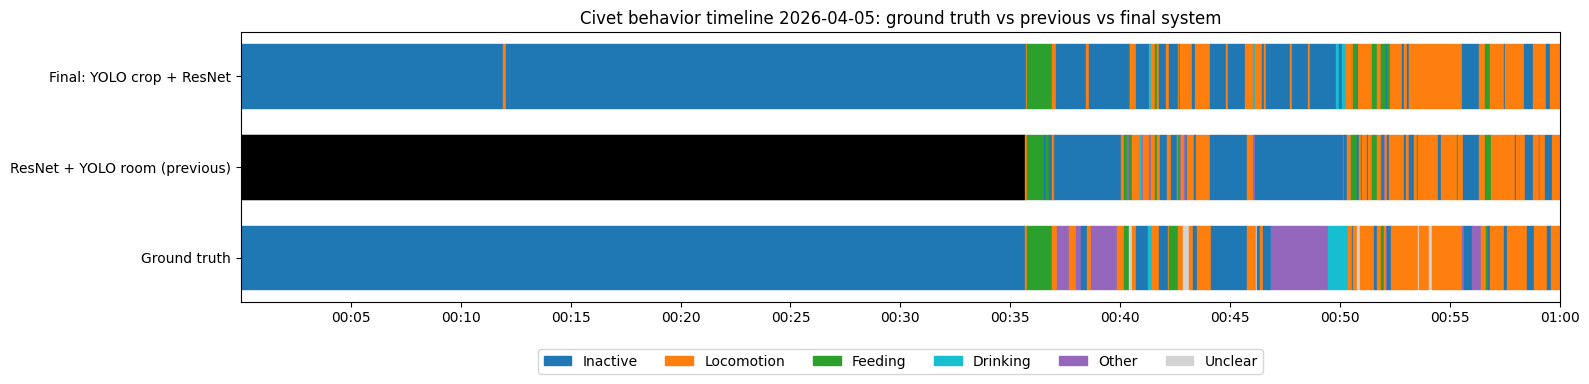

,system_s,ground_truth_s,system_%,ground_truth_%
Inactive,2803,2435,77.8,67.6
Locomotion,629,631,17.5,17.5
Feeding,136,119,3.8,3.3
Drinking,34,66,0.9,1.8
Other,0,304,0.0,8.4
Unclear,0,47,0.0,1.3


Saved: /content/drive/MyDrive/civet2/results/cc9_final_observation_sheet.xlsx


In [22]:
# ===== Cell C9: Final system — YOLO crop + ResNet + move rule =====
# Needs: C7 and C8 in this session (ground truth, helper functions, cam_df)
# Output: cc9_final_timeline.csv, cc9_final_timeline.png, cc9_final_observation_sheet.xlsx
FINAL = (0, 1, 0)   # (distance-Other, move rule, motion-Other): Other detectors off (C8)

cam_df['lab'] = [label(r, *FINAL) for _, r in cam_df.iterrows()]
comb = tl[['sec']].merge(combine(cam_df), on='sec', how='left')
room = smooth(comb['room'].fillna('A02'))
beh = [split_fd(b, r) for b, r in zip(smooth(comb['beh'].fillna('Inactive')), room)]
fin = pd.DataFrame({'sec': tl['sec'], 'time': tl['sec'].map(fmt),
                    'room': room, 'behavior': beh})
fin['status'] = fin['behavior'].map(status)
fin['gt_behavior'] = tl['gt_beh']
fin.to_csv(RESULTS / 'cc9_final_timeline.csv', index=False)

# ---------- Final scores (same definitions as C7 / C8) ----------
y, p = tl.loc[ai_mask, 'gt_status'], fin.loc[ai_mask, 'status']
final_row = score('Final: YOLO crop + ResNet + move rule', combine(cam_df))
final_row['active_inactive_acc'] = round((y == p).mean(), 3)
final_row['system'] = final_row.pop('variant')
table = pd.concat([comp[comp['system'] == 'ResNet + YOLO room (previous)'],
                   pd.DataFrame([final_row]),
                   comp[comp['system'].isin(['Baseline: always Active', 'Ground truth'])]],
                  ignore_index=True)
table = table.drop(columns=['other_recall', 'false_other_rate'], errors='ignore')
table.to_csv(RESULTS / 'cc9_final_comparison.csv', index=False)
display(table.set_index('system').T)

# ---------- Timeline: ground truth vs previous vs final ----------
lines = [('Ground truth', tl['gt_beh']),
         ('ResNet + YOLO room (previous)', out['ResNet + YOLO room (previous)']['beh']),
         ('Final: YOLO crop + ResNet', fin['behavior'])]
fig, ax = plt.subplots(figsize=(16, 4))
for yy, (name, labels) in enumerate(lines):
    for x0, w, lab in bars(labels):
        ax.broken_barh([(x0, w)], (yy - 0.35, 0.7), color=COL.get(lab, 'black'))
ax.set_yticks(range(len(lines)), [l[0] for l in lines])
ax.set_xticks(ticks, [fmt(t)[:5] for t in ticks])
ax.set_xlim(t0, t1)
ax.legend(handles, COL.keys(), ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.15))
ax.set_title(f'Civet behavior timeline {DATE}: ground truth vs previous vs final system')
plt.tight_layout()
plt.savefig(RESULTS / 'cc9_final_timeline.png', dpi=120)
plt.show()

# ---------- Observation sheet ----------
ev_rows = []
for who, labels in [('System', fin['behavior']), ('Ground truth', tl['gt_beh'])]:
    for target in ['Feeding', 'Drinking']:
        for a, b in events(tl['sec'], labels, target):
            ev_rows.append({'source': who, 'behavior': target,
                            'start': fmt(a), 'end': fmt(b),
                            'duration_s': b - a + 1, 'start_sec': a})
ev = pd.DataFrame(ev_rows, columns=ev_cols)

fin['minute'] = fin['sec'] // 60 * 60
minute_rows = []
for m, g in fin.groupby('minute'):
    st = ev[(ev['source'] == 'System') & (ev['start_sec'] // 60 * 60 == m)]
    minute_rows.append({
        'date': DATE, 'time': fmt(m)[:5],
        'room': ROOM[g['room'].mode()[0]],
        'behavior': g['behavior'].mode()[0],
        'status': g['status'].mode()[0],
        'active_s': int((g['status'] == 'Active').sum()),
        'inactive_s': int((g['status'] == 'Inactive').sum()),
        'feeding_events': int((st['behavior'] == 'Feeding').sum()),
        'drinking_events': int((st['behavior'] == 'Drinking').sum()),
        'gt_behavior': g['gt_behavior'].mode()[0]})

sys_s = fin['behavior'].value_counts().reindex(BEH, fill_value=0)
gt_s = tl['gt_beh'].value_counts().reindex(BEH, fill_value=0)
beh_sum = pd.DataFrame({'system_s': sys_s, 'ground_truth_s': gt_s})
beh_sum['system_%'] = (beh_sum['system_s'] / len(fin) * 100).round(1)
beh_sum['ground_truth_%'] = (beh_sum['ground_truth_s'] / len(fin) * 100).round(1)
display(beh_sum)

xlsx = RESULTS / 'cc9_final_observation_sheet.xlsx'
with pd.ExcelWriter(xlsx) as w:
    pd.DataFrame(minute_rows).to_excel(w, sheet_name='Timeline', index=False)
    beh_sum.to_excel(w, sheet_name='Behavior summary')
    ev.drop(columns='start_sec').to_excel(w, sheet_name='Events', index=False)
    table.to_excel(w, sheet_name='Comparison', index=False)
    abl.to_excel(w, sheet_name='Ablation', index=False)
print('Saved:', xlsx)

In [25]:
# ===== Cell C9b: Final system scores on two windows + majority baseline =====
# Input : cc9_final_timeline.csv, test/hour_labels.csv | Output: cc9b_windows.csv
from sklearn.metrics import balanced_accuracy_score
fin = pd.read_csv(RESULTS / 'cc9_final_timeline.csv')     # sec, time, room, behavior, status, gt_behavior
hl = pd.read_csv(BASE / 'test' / 'hour_labels.csv')
gt_room = {}
for r in hl.itertuples():
    room = 'A02' if r.behavior == 'In_box' else r.camera
    for s in range(hms(r.start), hms(r.end) + 1):
        gt_room[s] = room
fin['gt_room'] = [gt_room.get(s, 'A02') for s in fin['sec']]
fin['gt_status'] = fin['gt_behavior'].map(
    lambda b: 'Inactive' if b == 'Inactive' else ('Active' if b in ('Locomotion', 'Feeding', 'Drinking', 'Other') else None))

def scores(d, name):
    ok = d['gt_behavior'] != 'Unclear'
    tr = ok & d['gt_behavior'].isin(['Inactive', 'Locomotion', 'Feeding', 'Drinking'])
    ai = d['gt_status'].notna()
    y, p = d.loc[ai, 'gt_status'], d.loc[ai, 'status']
    return {'window': name, 'seconds': len(d),
            'behavior_acc': round((d.loc[ok, 'behavior'] == d.loc[ok, 'gt_behavior']).mean(), 3),
            'behavior_acc_trained_only': round((d.loc[tr, 'behavior'] == d.loc[tr, 'gt_behavior']).mean(), 3),
            'active_inactive_acc': round((y == p).mean(), 3),
            'active_inactive_balanced': round(balanced_accuracy_score(y, p), 3),
            'inactive_recall': round(((p == 'Inactive') & (y == 'Inactive')).sum() / (y == 'Inactive').sum(), 3),
            'active_recall': round(((p == 'Active') & (y == 'Active')).sum() / (y == 'Active').sum(), 3),
            'room_acc': round((d.loc[ok, 'room'] == d.loc[ok, 'gt_room']).mean(), 3),
            'majority_baseline_ai_acc': round(max((y == 'Active').mean(), (y == 'Inactive').mean()), 3),
            'majority_class': 'Active' if (y == 'Active').mean() > 0.5 else 'Inactive'}

win = pd.DataFrame([scores(fin, 'Whole clip (00:00:00-01:00:01)'),
                    scores(fin[fin['sec'] >= hms('00:35:39')], 'Civet out of the box (00:35:39-01:00:01)')])
win.to_csv(RESULTS / 'cc9b_windows.csv', index=False)
display(win.set_index('window').T)

window,Whole clip (00:00:00-01:00:01),Civet out of the box (00:35:39-01:00:01)
seconds,3602,1463
behavior_acc,0.835,0.591
behavior_acc_trained_only,0.914,0.753
active_inactive_acc,0.852,0.633
active_inactive_balanced,0.784,0.676
inactive_recall,0.967,0.75
active_recall,0.602,0.602
room_acc,0.952,0.879
majority_baseline_ai_acc,0.685,0.791
majority_class,Inactive,Active


## Step C10: Zoo-style Observation Sheet
Final output in the same layout as the Chiang Mai Zoo paper sheet (Duration + Frequency), system vs ground truth.

In [26]:
# ===== Cell C10: Zoo-style observation sheet (Duration + Frequency) =====
# Same layout as the Chiang Mai Zoo paper sheet: Duration (Inactive / Active / Not visible bouts)
# and Frequency (event counts per hour). One sheet for the system, one for the ground truth.
# Needs: Step 1 setup (BASE, RESULTS). Input : cc9_final_timeline.csv, y7_detections.csv, test/hour_labels.csv
# Output: cc10_zoo_observation_sheet.xlsx
import pandas as pd
from openpyxl import Workbook
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side

MIN_BOUT_S   = 60   # bouts shorter than 1 min are merged into the previous bout (keeper sheets use minutes)
GAP_S        = 5    # no camera sees the civet for longer than this -> Not visible
MERGE_GAP_S  = 60   # event rule (same as C7-C9): gaps < 60 s merged
MIN_EVENT_S  = 5    #                             events < 5 s ignored
DATE_TXT     = '05-04-2026'
INACTIVE     = {'Inactive', 'Resting', 'Sitting', 'Standing', 'In_box'}

fin = pd.read_csv(RESULTS / 'cc9_final_timeline.csv')           # sec, time, room, behavior, status, gt_behavior
det = pd.read_csv(RESULTS / 'y7_detections.csv')                # camera, sec, n_det, ...
gt_lab = pd.read_csv(BASE / 'test' / 'hour_labels.csv')         # start, end, camera, behavior, note
secs = fin['sec'].to_numpy()
t0, t1 = int(secs.min()), int(secs.max())

def hhmm(s):            # seconds after midnight -> '00.35' (keeper sheet style)
    s = int(s); return f'{s // 3600:02d}.{s % 3600 // 60:02d}'

def to_sec(t):
    h, m, s = map(int, str(t).split(':')); return h * 3600 + m * 60 + s

def runs(labels):
    """Run-length encode a per-second label list -> [[label, start_idx, end_idx], ...]."""
    out = []
    for i, lab in enumerate(labels):
        if out and out[-1][0] == lab: out[-1][2] = i
        else: out.append([lab, i, i])
    return out

def merge_short(rs, min_len):
    """Merge bouts shorter than min_len into the previous bout (first bout -> next bout)."""
    changed = True
    while changed and len(rs) > 1:
        changed = False
        for k, (lab, a, b) in enumerate(rs):
            if b - a + 1 < min_len:
                if k > 0: rs[k - 1][2] = b
                else:     rs[k + 1][1] = a
                rs.pop(k); changed = True
                # join neighbours that now have the same label
                out = [rs[0]]
                for r in rs[1:]:
                    if r[0] == out[-1][0]: out[-1][2] = r[2]
                    else: out.append(r)
                rs[:] = out
                break
    return rs

def events(labels, target):
    """Start seconds of events of one behavior (same merge / minimum rules as C9)."""
    ev = []
    for lab, a, b in runs(list(labels)):
        if lab != target: continue
        if ev and a - ev[-1][1] - 1 < MERGE_GAP_S: ev[-1][1] = b
        else: ev.append([a, b])
    return [int(secs[a]) for a, b in ev if b - a + 1 >= MIN_EVENT_S]

# ---------- Per-second status: system ----------
seen = det[det['sec'].between(t0, t1)].groupby('sec')['n_det'].max().reindex(secs, fill_value=0) > 0
sys_status = fin['status'].where(fin['status'].isin(['Active', 'Inactive']), 'Inactive').tolist()
for lab, a, b in runs(seen.tolist()):
    if not lab and b - a + 1 > GAP_S:
        sys_status[a:b + 1] = ['Not visible'] * (b - a + 1)

# ---------- Per-second status: ground truth ----------
gt_beh = fin['gt_behavior'].fillna('Unclear').tolist()
inbox = set()                                        # hand-labeled "in the box" seconds
for r in gt_lab[gt_lab['behavior'] == 'In_box'].itertuples():
    inbox.update(range(to_sec(r.start), to_sec(r.end) + 1))
gt_status = []
for s, b in zip(secs, gt_beh):
    if s in inbox: gt_status.append('Not visible')
    elif b in INACTIVE: gt_status.append('Inactive')
    elif b == 'Unclear': gt_status.append(gt_status[-1] if gt_status else 'Inactive')
    else: gt_status.append('Active')                    # Locomotion, Feeding, Drinking, Other

# ---------- Ground-truth counts of untrained behaviors (from hour_labels.csv notes) ----------
def note_events(keys):
    rows = gt_lab[gt_lab['behavior'].eq('Other') & gt_lab['note'].fillna('').str.contains('|'.join(keys), case=False)]
    return [to_sec(s) for s in rows['start'] if t0 <= to_sec(s) <= t1]

COLS = ['Feeding', 'Drinking', 'Territorial marking', 'Grooming', 'Urine', 'Feces']
freq_sys = {'Feeding': events(fin['behavior'], 'Feeding'), 'Drinking': events(fin['behavior'], 'Drinking'),
            'Territorial marking': None, 'Grooming': None, 'Urine': None, 'Feces': None}  # None = not detected by the model
freq_gt = {'Feeding': events(gt_beh, 'Feeding'), 'Drinking': events(gt_beh, 'Drinking'),
           'Territorial marking': note_events(['territ']), 'Grooming': note_events(['groom']),
           'Urine': note_events(['urin']), 'Feces': note_events(['defec', 'fece'])}

# ---------- Excel layout ----------
TEAL, CREAM = PatternFill('solid', fgColor='1F6F78'), PatternFill('solid', fgColor='FCE9C9')
thin = Side(style='thin', color='000000'); BOX = Border(left=thin, right=thin, top=thin, bottom=thin)
MID = Alignment(horizontal='center', vertical='center', wrap_text=True)

def cell(ws, r, c, v='', bold=False, fill=None, color='000000', size=11):
    x = ws.cell(row=r, column=c)
    if type(x).__name__ != 'MergedCell':
        x.value = v
    x.font, x.alignment, x.border = Font(bold=bold, color=color, size=size), MID, BOX
    if fill: x.fill = fill
    return x

def write_sheet(ws, title, recorder, status, freq):
    ws.merge_cells('A1:Q1'); cell(ws, 1, 1, f'Observation sheet — Large spotted civet  ({title})', True, TEAL, 'FFFFFF', 14)
    ws.merge_cells('A2:Q2'); cell(ws, 2, 1, f'Date: {DATE_TXT}    Time: {hhmm(t0)}-{hhmm(t1)}    Cameras: A01-A04    Recorder: {recorder}')

    # Duration table (columns A-I)
    groups = ['Inactive', 'Active', 'Mating behavior', 'Not visible']
    ws.merge_cells('A4:A5'); cell(ws, 4, 1, 'No', True, CREAM)
    for g, name in enumerate(groups):
        c = 2 + 2 * g
        ws.merge_cells(start_row=4, start_column=c, end_row=4, end_column=c + 1)
        cell(ws, 4, c, name, True, CREAM); cell(ws, 4, c + 1, '', fill=CREAM)
        cell(ws, 5, c, 'Start', True, CREAM); cell(ws, 5, c + 1, 'Stop', True, CREAM)
    bouts = {g: [] for g in groups}
    for lab, a, b in merge_short(runs(status), MIN_BOUT_S):
        bouts[lab].append((int(secs[a]), int(secs[b]) + 1))
    n = max(1, max(len(v) for v in bouts.values()))
    for i in range(n):
        r = 6 + i; cell(ws, r, 1, i + 1)
        for g, name in enumerate(groups):
            c = 2 + 2 * g
            s, e = bouts[name][i] if i < len(bouts[name]) else ('', '')
            cell(ws, r, c, hhmm(s) if s != '' else ''); cell(ws, r, c + 1, hhmm(e) if e != '' else '')
    r = 6 + n; cell(ws, r, 1, 'Total', True, CREAM)
    for g, name in enumerate(groups):
        c = 2 + 2 * g
        mins = sum(e - s for s, e in bouts[name]) / 60
        ws.merge_cells(start_row=r, start_column=c, end_row=r, end_column=c + 1)
        cell(ws, r, c, f'{mins:.0f} min' if name != 'Mating behavior' else '-', True, CREAM); cell(ws, r, c + 1, '', fill=CREAM)

    # Frequency table (columns K-Q)
    ws.merge_cells('K4:K5'); cell(ws, 4, 11, 'Time', True, CREAM)
    ws.merge_cells('L4:Q4'); cell(ws, 4, 12, 'Frequency (times)', True, CREAM)
    for j, name in enumerate(COLS): cell(ws, 5, 12 + j, name, True, CREAM)
    hours = range(t0 // 3600, (t1 - 1) // 3600 + 1)
    for i, h in enumerate(hours):
        r = 6 + i; cell(ws, r, 11, f'{h:02d}.00-{h + 1:02d}.00')
        for j, name in enumerate(COLS):
            v = freq[name]
            k = None if v is None else sum(1 for s in v if s // 3600 == h)
            cell(ws, r, 12 + j, 'n/a' if k is None else ('/' * k if k else ''), size=12)
    r = 6 + len(hours); cell(ws, r, 11, 'Total', True, CREAM)
    for j, name in enumerate(COLS):
        v = freq[name]; cell(ws, r, 12 + j, 'n/a' if v is None else len(v), True, CREAM)
    note_r = max(6 + n, 6 + len(hours)) + 2
    ws.merge_cells(start_row=note_r, start_column=1, end_row=note_r, end_column=17)
    cell(ws, note_r, 1, 'n/a = behavior not detected by the model (no training images). '
         f'Bouts < {MIN_BOUT_S} s merged into the previous bout; Not visible = no camera sees the civet for > {GAP_S} s.')

    for col, w in zip('ABCDEFGHIJKLMNOPQ', [5, 8, 8, 8, 8, 9, 9, 9, 9, 2, 13, 9, 9, 11, 10, 8, 8]):
        ws.column_dimensions[col].width = w
    return bouts

wb = Workbook()
ws_sys = wb.active; ws_sys.title = 'System'
b_sys = write_sheet(ws_sys, 'automatic', 'System (YOLO crop + ResNet18 + move rule)', sys_status, freq_sys)
b_gt = write_sheet(wb.create_sheet('Ground truth'), 'manual', 'Team (hand-labeled)', gt_status, freq_gt)

# ---------- Comparison sheet ----------
ws = wb.create_sheet('Comparison')
rows = [['Item', 'System', 'Ground truth']]
for name in ['Inactive', 'Active', 'Not visible']:
    rows.append([f'{name} (min)', round(sum(e - s for s, e in b_sys[name]) / 60, 1), round(sum(e - s for s, e in b_gt[name]) / 60, 1)])
for name in COLS:
    rows.append([f'{name} (times)', 'n/a' if freq_sys[name] is None else len(freq_sys[name]), len(freq_gt[name])])
for i, row in enumerate(rows):
    for j, v in enumerate(row):
        cell(ws, i + 1, j + 1, v, bold=(i == 0), fill=CREAM if i == 0 else None)
ws.column_dimensions['A'].width, ws.column_dimensions['B'].width, ws.column_dimensions['C'].width = 26, 12, 14

out = RESULTS / 'cc10_zoo_observation_sheet.xlsx'
wb.save(out)
display(pd.DataFrame(rows[1:], columns=rows[0]).astype(str).set_index('Item'))
print('Saved:', out)

,System,Ground truth
Item,,
Inactive (min),13.7,2.7
Active (min),10.6,21.7
Not visible (min),35.7,35.6
Feeding (times),3,4.0
Drinking (times),3,2.0
Territorial marking (times),n/a,0.0
Grooming (times),n/a,5.0
Urine (times),n/a,1.0
Feces (times),n/a,1.0


Saved: /content/drive/MyDrive/civet2/results/cc10_zoo_observation_sheet.xlsx


### Step C10b: System Result in the Hand-label Format
Same columns as `hour_labels.csv` (start, end, camera, behavior, note) for a direct comparison.

In [27]:
# ===== Cell C10b: System result in the same format as the hand labels (hour_labels.csv) =====
# Needs: Step 1 setup (BASE, RESULTS). Input : cc9_final_timeline.csv, test/hour_labels.csv
# Output: cc10_system_labels.csv, cc10_labels_side_by_side.xlsx
import pandas as pd

MIN_SEG_S = 5                       # same rule as the hand labels: segments < 5 s are not split
NAME = {'Inactive': 'Resting'}      # use the same behavior names as hour_labels.csv

fin = pd.read_csv(RESULTS / 'cc9_final_timeline.csv')      # sec, time, room, behavior, status, gt_behavior
gt = pd.read_csv(BASE / 'test' / 'hour_labels.csv')        # start, end, camera, behavior, note

def fmt(s):
    s = int(s); return f'{s // 3600:02d}:{s % 3600 // 60:02d}:{s % 60:02d}'

# ---------- Per-second (room, behavior) -> segments ----------
segs = []
for s, room, beh in zip(fin['sec'], fin['room'], fin['behavior']):
    lab = (room, NAME.get(beh, beh))
    if segs and segs[-1][2] == lab: segs[-1][1] = s
    else: segs.append([s, s, lab])

# Merge segments shorter than MIN_SEG_S into the previous one
merged = []
for a, b, lab in segs:
    if merged and (b - a + 1 < MIN_SEG_S or merged[-1][2] == lab):
        merged[-1][1] = b
    else:
        merged.append([a, b, lab])

sys_lab = pd.DataFrame([{'start': fmt(a), 'end': fmt(b), 'camera': lab[0],
                         'behavior': lab[1], 'note': ''} for a, b, lab in merged])
sys_lab.to_csv(RESULTS / 'cc10_system_labels.csv', index=False)

# ---------- Side by side with the hand labels (same time window) ----------
t0, t1 = fmt(fin['sec'].min()), fmt(fin['sec'].max())
gt_win = gt[(gt['end'].astype(str) >= t0) & (gt['start'].astype(str) <= t1)]
xlsx = RESULTS / 'cc10_labels_side_by_side.xlsx'
with pd.ExcelWriter(xlsx) as w:
    sys_lab.to_excel(w, sheet_name='System', index=False)
    gt_win.to_excel(w, sheet_name='Ground truth', index=False)

print(f'Window {t0}-{t1} | system segments: {len(sys_lab)} | ground-truth segments: {len(gt_win)}')
display(sys_lab.head(15))
print('Saved:', RESULTS / 'cc10_system_labels.csv')
print('Saved:', xlsx)

Window 00:00:00-01:00:01 | system segments: 87 | ground-truth segments: 98


,start,end,camera,behavior,note
0,00:00:00,00:11:56,A02,Resting,
1,00:11:57,00:12:02,A02,Locomotion,
2,00:12:03,00:35:44,A02,Resting,
3,00:35:45,00:36:54,A03,Feeding,
4,00:36:55,00:37:03,A02,Locomotion,
5,00:37:04,00:37:38,A01,Resting,
6,00:37:39,00:38:26,A02,Resting,
7,00:38:27,00:38:34,A02,Locomotion,
8,00:38:35,00:40:25,A02,Resting,
9,00:40:26,00:40:42,A03,Locomotion,


Saved: /content/drive/MyDrive/civet2/results/cc10_system_labels.csv
Saved: /content/drive/MyDrive/civet2/results/cc10_labels_side_by_side.xlsx
